# Notebook 2 · Perfiles de trayectoria LSPB (Linear Segment with Parabolic Blends)

**IMT-342 Robótica · Hito 2.** Dada la postura actual $q_0$ y la meta $q_f$ (salida de Pieper), generar una trayectoria **suave**: arranque parabólico a aceleración constante, tramo lineal a velocidad constante y frenado simétrico.

Todas las juntas comparten el tiempo total $t_f$ y el tiempo de mezcla $t_b$, así que llegan a la vez:

$$V_i=\frac{\Delta_i}{t_f-t_b},\qquad a_i=\frac{V_i}{t_b}$$

El menor $t_f$ factible respeta $|V_i|\le v_{max,i}$ y $|a_i|\le a_{max,i}$ y se halla por bisección.

In [1]:
import sys
from pathlib import Path
import numpy as np
import warnings
warnings.filterwarnings("ignore", message="Unable to import Axes3D")
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().resolve().parent))   # carpeta hito2/ (paquete irb120)
np.set_printoptions(precision=4, suppress=True)

from irb120.lspb import plan_lspb
from irb120.dh import forward_kinematics_tcp

VMAX = np.deg2rad([250, 250, 250, 320, 320, 420])     # limites ABB IRB 120 [rad/s]
q0 = np.zeros(6)
qf = np.deg2rad([60, -40, 20, 90, 30, -120])

## 1. Planificación con el 30 % de la velocidad máxima y 3 rad/s²

In [2]:
traj = plan_lspb(q0, qf, VMAX * 0.3, 3.0)
print(f"tf = {traj.tf:.3f} s   tb = {traj.tb:.3f} s")
print("velocidad de crucero [deg/s]:", np.rad2deg(traj.cruise_velocity).round(1))
print("aceleracion de mezcla [rad/s2]:", traj.blend_acceleration.round(3))
print("junta que satura la aceleracion:", int(np.argmax(np.abs(traj.blend_acceleration))) + 1)

tf = 1.685 s   tb = 0.733 s
velocidad de crucero [deg/s]: [  63.   -42.    21.    94.5   31.5 -126. ]
aceleracion de mezcla [rad/s2]: [ 1.5  -1.    0.5   2.25  0.75 -3.  ]
junta que satura la aceleracion: 6


## 2. Perfiles de posición, velocidad y aceleración

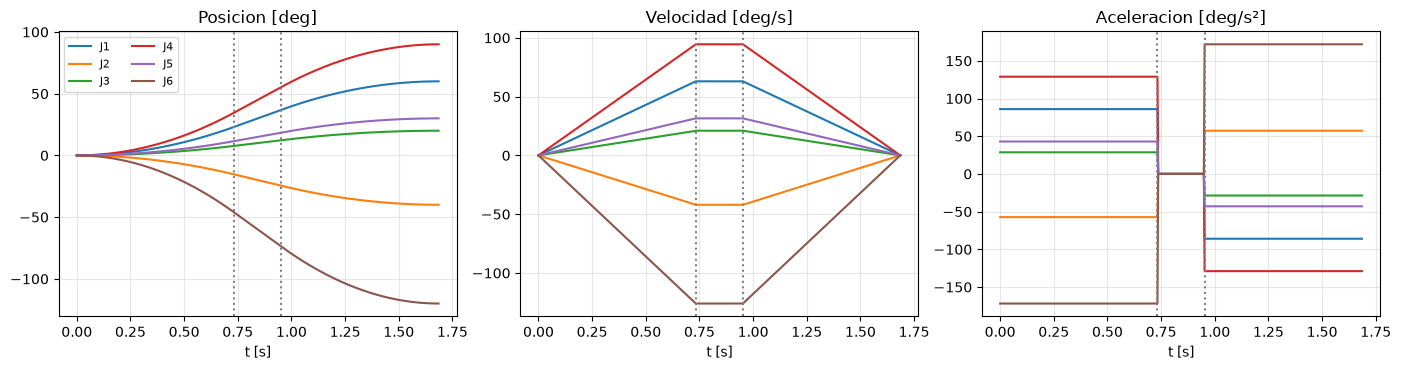

In [3]:
t = np.linspace(0, traj.tf, 500)
q, v, a = (np.degrees(np.array([traj.sample(x)[i] for x in t])) for i in range(3))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for axis, data, title in zip(ax, (q, v, a), ("Posicion [deg]", "Velocidad [deg/s]", "Aceleracion [deg/s²]")):
    axis.plot(t, data); axis.axvline(traj.tb, c="gray", ls=":"); axis.axvline(traj.tf - traj.tb, c="gray", ls=":")
    axis.set(xlabel="t [s]", title=title); axis.grid(alpha=.3)
ax[0].legend([f"J{i+1}" for i in range(6)], ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

## 3. Comprobaciones: extremos en reposo, continuidad y sincronía

In [4]:
start, end = traj.sample(0.0), traj.sample(traj.tf)
assert np.allclose(start[0], q0) and np.allclose(end[0], qf)
assert np.allclose(start[1], 0) and np.allclose(end[1], 0)
for instant in (traj.tb, traj.tf - traj.tb):
    before, after = traj.sample(instant - 1e-9), traj.sample(instant + 1e-9)
    assert np.allclose(before[0], after[0], atol=1e-6) and np.allclose(before[1], after[1], atol=1e-6)
assert np.allclose(traj.sample(traj.tf / 2)[0], (q0 + qf) / 2)           # todas llegan a la vez
times = np.linspace(0, traj.tf, 4001)
vel = np.array([traj.sample(x)[1] for x in times])
integral = np.sum(0.5 * (vel[1:] + vel[:-1]) * np.diff(times)[:, None], axis=0)
assert np.allclose(integral, qf - q0, atol=1e-5)
assert np.all(np.abs(traj.cruise_velocity) <= VMAX * 0.3 + 1e-9) and np.all(np.abs(traj.blend_acceleration) <= 3.0 + 1e-9)
print("OK: reposo en los extremos, continuidad C1, sincronia, integral de v = Delta q y limites respetados")

OK: reposo en los extremos, continuidad C1, sincronia, integral de v = Delta q y limites respetados


## 4. Efecto de la velocidad y de la aceleración máximas

 speed_scale   amax   tf [s]   tb [s]
         0.1    1.0    3.590    0.733
         0.1    3.0    3.101    0.244
         0.1    8.0    2.949    0.092
         0.3    1.0    2.894    1.447
         0.3    3.0    1.685    0.733
         0.3    8.0    1.227    0.275
         0.6    1.0    2.894    1.447
         0.6    3.0    1.671    0.836
         0.6    8.0    1.023    0.512
         1.0    1.0    2.894    1.447
         1.0    3.0    1.671    0.836
         1.0    8.0    1.023    0.512


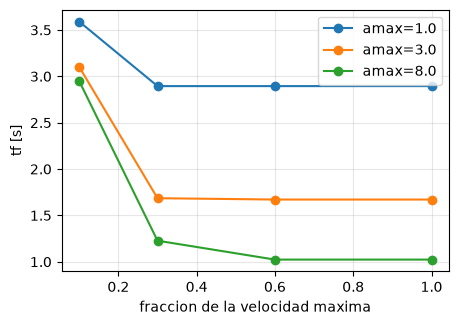

In [5]:
print(f"{'speed_scale':>12} {'amax':>6} {'tf [s]':>8} {'tb [s]':>8}")
rows = []
for scale in (0.1, 0.3, 0.6, 1.0):
    for amax in (1.0, 3.0, 8.0):
        tr = plan_lspb(q0, qf, VMAX * scale, amax)
        rows.append((scale, amax, tr.tf)); print(f"{scale:12.1f} {amax:6.1f} {tr.tf:8.3f} {tr.tb:8.3f}")
plt.figure(figsize=(5, 3.4))
for amax in (1.0, 3.0, 8.0):
    plt.plot([r[0] for r in rows if r[1] == amax], [r[2] for r in rows if r[1] == amax], "o-", label=f"amax={amax}")
plt.xlabel("fraccion de la velocidad maxima"); plt.ylabel("tf [s]"); plt.legend(); plt.grid(alpha=.3); plt.show()

## 5. Trayectoria del TCP resultante
Al interpolar en el espacio articular el TCP describe una curva suave (no una recta); aquí se proyecta sobre x–z y x–y.

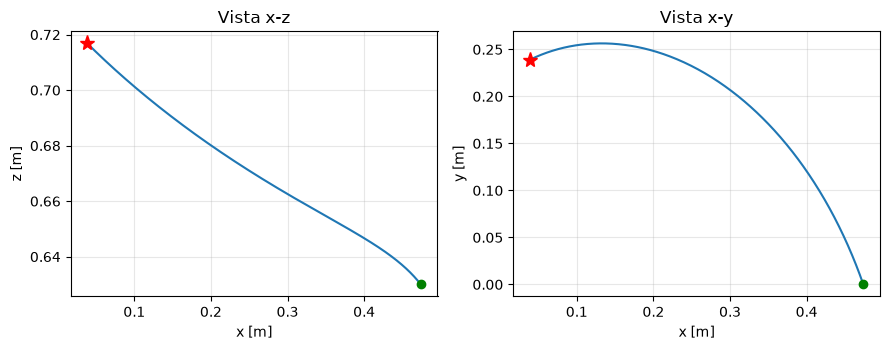

TCP inicial [m]: [0.474 0.    0.63 ]  final [m]: [0.0387 0.239  0.7168]


In [6]:
tcp = np.array([forward_kinematics_tcp(traj.sample(x)[0])[:3, 3] for x in t])
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ax[0].plot(tcp[:, 0], tcp[:, 2]); ax[0].plot(*tcp[0, [0, 2]], "go"); ax[0].plot(*tcp[-1, [0, 2]], "r*", ms=11); ax[0].set(xlabel="x [m]", ylabel="z [m]", title="Vista x-z"); ax[0].grid(alpha=.3)
ax[1].plot(tcp[:, 0], tcp[:, 1]); ax[1].plot(*tcp[0, :2], "go"); ax[1].plot(*tcp[-1, :2], "r*", ms=11); ax[1].set(xlabel="x [m]", ylabel="y [m]", title="Vista x-y"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
print("TCP inicial [m]:", tcp[0], " final [m]:", tcp[-1])

## Conclusión
- El LSPB parte y termina en reposo, es continuo en posición y velocidad y mantiene todas las juntas sincronizadas.
- El tiempo total lo fija la junta más exigente (la 6 en este ejemplo); las demás reducen velocidad y aceleración para llegar a la vez.
- Subir la velocidad máxima solo acorta $t_f$ hasta que la aceleración pasa a ser el límite.